# XLM-RoBERTa-base — pemodelan hate speech per bahasa

Notebook mandiri untuk checkpoint **`FacebookAI/xlm-roberta-base`** pada StereoQueerEval.
Eksperimen **EN**, **IT**, dan **NL** dijalankan terpisah: setiap bahasa memulai dari
model pretrained baru, memakai split bahasa tersebut, dan memperoleh artefaknya sendiri.
Satu notebook dapat dipakai untuk semua bahasa atau hanya bahasa tugas satu anggota tim.

**Status: draft untuk ditinjau; semua sel belum dijalankan.**
Jalankan sel berurutan dari atas pada runtime GPU setelah konfigurasi disepakati.

| Subset | Fungsi |
|---|---|
| Train | Melatih bobot dan menghitung class weight hanya dari train bahasa aktif. |
| Validation | Evaluasi per epoch, early stopping, dan pemilihan checkpoint dengan macro-F1 terbaik. |
| Test | Evaluasi akhir setelah checkpoint dipilih. Hasil test tidak dipakai untuk tuning. |

Fitur: **`yt_comment`**. Target: **`hate_speech`** dengan urutan kelas
`no=0`, `yes_implicit=1`, `yes_explicit=2`.
Kolom judul, deskripsi, stereotype, dan target tidak dijadikan fitur model.
Judul/deskripsi hanya digunakan dalam audit overlap konteks antar-split.

Pembagian data mengikuti `Analisis/data/ringkasan_splitting.md`; tidak ada splitting ulang,
penggabungan bahasa, atau pemindahan sampel antar-subset.
Test ini adalah **test internal dari training release**, bukan official held-out test.

| Bahasa | Train | Validation | Test |
|---|---:|---:|---:|
| EN — English | 2.111 | 292 | 586 |
| IT — Italian | 1.699 | 220 | 481 |
| NL — Dutch | 1.556 | 226 | 456 |


## 1. Siapkan runtime cloud dan direktori data

Gunakan Python **3.11 atau 3.12**, satu GPU CUDA, dan internet untuk mengunduh checkpoint.
Di Colab, aktifkan **Runtime → Change runtime type → GPU**.
Di Modal, jalankan notebook pada lingkungan Python dengan GPU; mount/salin data ke input
dan arahkan output ke penyimpanan persisten. Runner/deployment Modal diatur terpisah.

Struktur direktori yang sama dipakai pada kedua platform:

```text
DATA_ROOT/
├── en-splitting/
│   ├── en-train.csv
│   ├── en-val.csv
│   └── en-test.csv
├── it-splitting/
│   ├── it-train.csv
│   ├── it-val.csv
│   └── it-test.csv
└── nl-splitting/
    ├── nl-train.csv
    ├── nl-val.csv
    └── nl-test.csv
```

Colab: unggah folder melalui panel Files atau aktifkan `UPLOAD_CSV_IN_COLAB` pada konfigurasi.
Dialog upload menerima file seperti `en-train.csv`, `en-val.csv`, dan `en-test.csv`,
lalu menempatkannya otomatis ke subfolder bahasa. Upload sembilan CSV untuk semua bahasa,
atau tiga CSV untuk bahasa terpilih. Manifest splitting, XLSX campuran, dan original tidak diperlukan.

**Sesuaikan `DATA_ROOT`, `OUTPUT_ROOT`, dan `LANGUAGES` pada bagian 3.**
Contoh Colab: input `/content/data`, output `/content/results`.
Contoh Modal: input `/data`, output `/outputs` pada volume yang telah di-mount.
Di repository, `Analisis/data` dicari otomatis.
Untuk Colab, download ZIP sebelum runtime berakhir atau arahkan output ke Drive.
Untuk Modal, sinkronkan hasil ke volume sesuai konfigurasi runner yang digunakan.


## 2. Impor library dan periksa GPU


In [1]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['USE_TF'] = '0'
os.environ['USE_FLAX'] = '0'

import gc
import hashlib
import importlib.metadata
import json
import platform
import re
import shutil
import subprocess
import sys
import unicodedata
from datetime import datetime, timezone
from itertools import combinations
from pathlib import Path
from uuid import uuid4

import emoji
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import transformers
from datasets import Dataset
from IPython.display import FileLink, display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from transformers import (
    AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
    EarlyStoppingCallback, Trainer, TrainingArguments, set_seed,
)

IN_COLAB = 'google.colab' in sys.modules
sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 100)
if transformers.__version__ != '4.57.1':
    raise RuntimeError('Environment kernel harus menggunakan transformers==4.57.1. Siapkan dependensi di luar notebook, lalu restart kernel jika versi paket berubah.')
if not torch.cuda.is_available():
    raise RuntimeError('Aktifkan runtime GPU CUDA (Colab: Runtime > Change runtime type > GPU).')
if torch.cuda.device_count() != 1:
    raise RuntimeError('Notebook ini dirancang untuk satu GPU per eksperimen. Pilih runtime dengan satu GPU.')
print('Python:', platform.python_version())
print('Transformers:', transformers.__version__)
print('PyTorch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('GPU:', torch.cuda.get_device_name(0))


c:\Users\solon\AppData\Local\Programs\Python\Python312\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.0.1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


Python: 3.12.8
Transformers: 4.57.1
PyTorch: 2.9.1+cu130 | CUDA: 13.0
GPU: NVIDIA GeForce RTX 3060 Ti


## 3. Konfigurasi eksperimen

Default menjalankan EN, IT, dan NL berurutan dengan pengaturan sama.
Ubah `LANGUAGES`, misalnya `['it']`, untuk membagi tugas; bagian bahasa lain dilewati.
Sel konfigurasi membuat ID run baru sehingga hasil run terdahulu tetap tersimpan.
Selesaikan ekspor bahasa aktif sebelum memulai run baru atau pindah bahasa.

Pengaturan awal mengikuti eksperimen sebelumnya: max length 384, learning rate 1e-5,
weight decay 0,01, batch size 16, maksimal 10 epoch, early stopping patience 3,
seed 42, FP16, dan weighted cross-entropy. Class weight dihitung untuk train setiap bahasa:
`jumlah_train / (jumlah_kelas × jumlah_train_di_kelas)`.
Gradient accumulation ditetapkan 1. Jika memori GPU kurang, kecilkan batch size dan catat
perubahan; samakan pengaturan antarmodel ketika membandingkan hasil.

Preprocessing: emoji menjadi ` [EMOJI] `, kemudian Unicode casefold.
Placeholder ikut berubah menjadi `[emoji]` dan diproses tokenizer biasa;
tidak ada special token baru. Aturan sama diterapkan pada train, validation, test, dan inferensi.
Pengaturan ini dapat dibahas sebelum eksperimen dijalankan.
Seed dan determinisme membantu replikasi; perbedaan GPU/versi paket tetap perlu dicatat.


In [2]:
MODEL_NAME = 'FacebookAI/xlm-roberta-base'
MODEL_REVISION = 'main'  # Untuk replikasi ketat, ganti dengan commit hash dari manifest run pertama.
LANGUAGES = ['en', 'it', 'nl']  # Bisa ['en'], ['it'], atau ['nl'] untuk membagi tugas antaranggota.
LANGUAGE_NAMES = {'en': 'English', 'it': 'Italian', 'nl': 'Dutch'}

# DATA_ROOT langsung berisi en-splitting/, it-splitting/, dan nl-splitting/.
candidates = [Path.cwd() / 'data', Path.cwd().parent / 'data', Path.cwd() / 'Analisis' / 'data']
DATA_ROOT = next(
    (path for path in candidates if any((path / f'{lang}-splitting').is_dir() for lang in LANGUAGE_NAMES)),
    Path('/content/data') if IN_COLAB else Path.cwd() / 'data',
).resolve()
OUTPUT_ROOT = (Path('/content/results') if IN_COLAB else Path.cwd() / 'results').resolve()
# Contoh Modal dengan direktori yang sudah di-mount:
# DATA_ROOT = Path('/data')
# OUTPUT_ROOT = Path('/outputs')
# Contoh Colab ke Google Drive setelah drive.mount('/content/drive'):
# OUTPUT_ROOT = Path('/content/drive/MyDrive/PTM/results')

UPLOAD_CSV_IN_COLAB = False  # True untuk memilih CSV lokal melalui dialog Colab.
SEED = 42
MAX_LENGTH = 384
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 0.01
NUM_TRAIN_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 3
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 16
GRADIENT_ACCUMULATION_STEPS = 1
USE_FP16 = True
USE_CLASS_WEIGHTS = True
REPLACE_EMOJI = True
APPLY_CASEFOLD = True
SAVE_BEST_MODEL = True

LABEL2ID = {'no': 0, 'yes_implicit': 1, 'yes_explicit': 2}
ID2LABEL = {value: key for key, value in LABEL2ID.items()}
CLASS_NAMES = list(LABEL2ID)
CLASS_IDS = list(ID2LABEL)
TEXT_COLUMN = 'yt_comment'
LABEL_COLUMN = 'hate_speech'
ID_COLUMN = 'StereoQueerEval_id'
if not LANGUAGES or len(LANGUAGES) != len(set(LANGUAGES)) or not set(LANGUAGES) <= set(LANGUAGE_NAMES):
    raise ValueError('LANGUAGES harus berisi kode unik dari en, it, nl.')
if GRADIENT_ACCUMULATION_STEPS != 1:
    raise ValueError('Gunakan gradient_accumulation_steps=1 untuk formula weighted loss dalam notebook ini.')
if MAX_LENGTH <= 0 or min(TRAIN_BATCH_SIZE, EVAL_BATCH_SIZE) <= 0:
    raise ValueError('MAX_LENGTH dan batch size harus positif.')

MODEL_SLUG = MODEL_NAME.rsplit('/', 1)[-1]
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:8]
RUN_ROOT = OUTPUT_ROOT / MODEL_SLUG / RUN_ID
RUN_ROOT.mkdir(parents=True, exist_ok=False)
EXPERIMENTS = {}
PREPROCESSING_CONFIG = {
    'input_column': TEXT_COLUMN, 'replace_emoji': REPLACE_EMOJI,
    'emoji_replacement': ' [EMOJI] ', 'casefold': APPLY_CASEFOLD,
    'max_length': MAX_LENGTH, 'truncation': True, 'padding': 'dynamic per batch',
    'add_emoji_special_token': False, 'label2id': LABEL2ID,
}
print('Model:', MODEL_NAME)
print('Bahasa:', LANGUAGES)
print('DATA_ROOT:', DATA_ROOT)
print('RUN_ROOT:', RUN_ROOT)


Model: FacebookAI/xlm-roberta-base
Bahasa: ['en', 'it', 'nl']
DATA_ROOT: E:\Projek\PTM\TBP\Analisis\data
RUN_ROOT: E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49


## 4. Upload opsional dan verifikasi lokasi split

Jika data sudah ada di `DATA_ROOT`, biarkan upload `False` dan jalankan verifikasi.
Pada Colab, aktifkan upload pada konfigurasi untuk memilih CSV dari komputer.
Proses dihentikan jika CSV untuk salah satu bahasa terpilih belum lengkap.


In [3]:
if UPLOAD_CSV_IN_COLAB:
    if not IN_COLAB:
        raise RuntimeError('Dialog upload khusus Colab. Pada Modal, salin/mount data ke DATA_ROOT.')
    from google.colab import files
    uploaded = files.upload()
    expected_names = {
        f'{lang}-{split}.csv': (lang, split)
        for lang in LANGUAGES for split in ('train', 'val', 'test')
    }
    for filename, content in uploaded.items():
        basename = Path(filename).name
        if basename not in expected_names:
            print('Diabaikan (nama tidak sesuai pola split):', basename)
            continue
        lang, split = expected_names[basename]
        target = DATA_ROOT / f'{lang}-splitting' / basename
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(content)
        print('Disimpan:', target)
    del uploaded

missing_paths = [
    DATA_ROOT / f'{lang}-splitting' / f'{lang}-{split}.csv'
    for lang in LANGUAGES for split in ('train', 'val', 'test')
    if not (DATA_ROOT / f'{lang}-splitting' / f'{lang}-{split}.csv').is_file()
]
if missing_paths:
    raise FileNotFoundError('Lengkapi file berikut atau ubah DATA_ROOT / LANGUAGES:\n' + '\n'.join(map(str, missing_paths)))
print('Seluruh CSV untuk bahasa terpilih tersedia. Tidak ada splitting ulang.')


Seluruh CSV untuk bahasa terpilih tersedia. Tidak ada splitting ulang.


## 5. Fungsi pembacaan, audit data, dan preprocessing

Sel ini mendefinisikan fungsi; pemanggilannya ada pada bagian tiap bahasa.
ID dibaca sebagai string dan teks asli dipertahankan pada kolom sumber.
Audit memeriksa kolom wajib, label, komentar kosong, ID berulang, dan overlap ID,
komentar yang dinormalisasi, serta konteks video antar-subset.
Data bermasalah dihentikan untuk diperiksa, tanpa drop atau perubahan split otomatis.
Pemeriksaan kelengkapan kelas pada test adalah audit struktur dan tidak memengaruhi pemilihan model.
Statistik pelatihan, termasuk class weight, berasal dari train saja.


In [4]:
def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    # JSON tidak mendukung angka inf/nan; pertahankan sebagai teks agar log tetap tersimpan.
    value = json.loads(json.dumps(value, ensure_ascii=False), parse_constant=str)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def normalize_for_audit(text):
    # Normalisasi sesuai ringkasan splitting, hanya digunakan untuk audit.
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFKC', str(text)).casefold()).strip()


def read_language_splits(language):
    frames, sources = {}, {}
    for split in ('train', 'val', 'test'):
        path = DATA_ROOT / f'{language}-splitting' / f'{language}-{split}.csv'
        frame = pd.read_csv(path, encoding='utf-8-sig', dtype=str, keep_default_na=False)
        required = {ID_COLUMN, TEXT_COLUMN, LABEL_COLUMN}
        if not required <= set(frame.columns):
            raise ValueError(f'{path.name}: kolom wajib yang hilang: {required - set(frame.columns)}')
        if frame.empty:
            raise ValueError(f'{path.name}: split kosong.')
        if frame[ID_COLUMN].str.strip().eq('').any() or frame[ID_COLUMN].duplicated().any():
            raise ValueError(f'{path.name}: ID kosong atau berulang dalam satu split.')
        if frame[TEXT_COLUMN].str.strip().eq('').any():
            raise ValueError(f'{path.name}: komentar kosong. Periksa data sumber, jangan drop otomatis.')
        invalid = set(frame[LABEL_COLUMN]) - set(LABEL2ID)
        absent = set(LABEL2ID) - set(frame[LABEL_COLUMN])
        if invalid or absent:
            raise ValueError(f'{path.name}: label tidak dikenal={invalid}, kelas tidak hadir={absent}.')
        frames[split] = frame
        sources[split] = {'path': str(path), 'sha256': file_sha256(path), 'rows': len(frame)}

    keys = {}
    for split, frame in frames.items():
        keys[split] = {
            'id': set(frame[ID_COLUMN]),
            'normalized_comment': {value for value in frame[TEXT_COLUMN].map(normalize_for_audit) if value},
        }
        if {'yt_title', 'yt_description'} <= set(frame.columns):
            contexts = zip(frame['yt_title'].map(normalize_for_audit), frame['yt_description'].map(normalize_for_audit))
            keys[split]['video_context'] = {pair for pair in contexts if any(pair)}
    checks = []
    for left, right in combinations(frames, 2):
        for kind in sorted(set(keys[left]) & set(keys[right])):
            overlap = keys[left][kind] & keys[right][kind]
            checks.append({'left': left, 'right': right, 'key': kind, 'overlap_count': len(overlap)})
            if overlap:
                raise ValueError(f'{language}: kebocoran {kind} antara {left} dan {right} ({len(overlap)}).')
    return frames, {'language': language, 'source_files': sources, 'overlap_checks': checks}


def preprocess_text(text):
    text = str(text)
    if REPLACE_EMOJI:
        text = emoji.replace_emoji(text, replace=' [EMOJI] ')
    if APPLY_CASEFOLD:
        text = text.casefold()
    return text


def prepare_language(language):
    """Baca split asli, audit, dan transformasi tetap yang sama pada semua subset."""
    if language in EXPERIMENTS:
        raise RuntimeError(f'{language} sudah disiapkan. Untuk eksperimen baru, jalankan ulang sel konfigurasi.')
    frames, audit = read_language_splits(language)
    output_dir = RUN_ROOT / language
    output_dir.mkdir(parents=True, exist_ok=False)
    for frame in frames.values():
        frame['text'] = frame[TEXT_COLUMN].map(preprocess_text)
        frame['labels'] = frame[LABEL_COLUMN].map(LABEL2ID).astype('int64')
        if frame['text'].str.strip().eq('').any():
            raise ValueError('Ada teks kosong setelah preprocessing. Periksa konfigurasi sebelum training.')
    summary_rows = []
    for split, frame in frames.items():
        counts = frame[LABEL_COLUMN].value_counts()
        summary_rows.append({'split': split, 'rows': len(frame), **{label: int(counts.get(label, 0)) for label in CLASS_NAMES}})
    split_summary = pd.DataFrame(summary_rows)
    train_counts = np.bincount(frames['train']['labels'], minlength=len(CLASS_NAMES))
    weights = len(frames['train']) / (len(CLASS_NAMES) * train_counts) if USE_CLASS_WEIGHTS else np.ones(len(CLASS_NAMES))
    weights = torch.tensor(weights, dtype=torch.float32)
    state = {
        'language': language, 'frames': frames, 'audit': audit, 'output_dir': output_dir,
        'class_weights': weights, 'split_summary': split_summary,
        'started_at': datetime.now(timezone.utc).isoformat(),
    }
    EXPERIMENTS[language] = state
    save_json(output_dir / 'data_audit.json', audit)
    save_json(output_dir / 'preprocessing_config.json', PREPROCESSING_CONFIG)
    save_json(output_dir / 'class_weights.json', dict(zip(CLASS_NAMES, weights.tolist())))
    split_summary.to_csv(output_dir / 'split_summary.csv', index=False)
    print(language.upper(), LANGUAGE_NAMES[language], '| output:', output_dir)
    display(split_summary)
    print('Class weights (hanya dari train):', dict(zip(CLASS_NAMES, weights.tolist())))
    return state


## 6. Fungsi tokenisasi, loss, dan pelatihan

Hanya train dan validation ditokenisasi sebelum training. Tokenizer berasal dari checkpoint
model ini; truncation mengikuti `MAX_LENGTH` dan padding dilakukan dinamis per batch.
Setiap bahasa menginisialisasi model baru; bobot hasil bahasa sebelumnya tidak diteruskan.
Validation dievaluasi tiap epoch. Early stopping dan checkpoint terbaik memakai
**macro-F1 validation**. Test tidak diberikan sebagai `eval_dataset` saat training.
Setelah training, bobot terbaik dimuat dan disimpan bersama tokenizer.


In [5]:
def compute_metrics(eval_prediction):
    logits = eval_prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    y_true = eval_prediction.label_ids
    y_pred = np.argmax(logits, axis=-1)
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'macro_f1': float(f1_score(y_true, y_pred, labels=CLASS_IDS, average='macro', zero_division=0)),
        'weighted_f1': float(f1_score(y_true, y_pred, labels=CLASS_IDS, average='weighted', zero_division=0)),
    }


class ClassWeightedTrainer(Trainer):
    def __init__(self, *args, class_weights, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
        self.model_accepts_loss_kwargs = False

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs['labels']
        features = {key: value for key, value in inputs.items() if key != 'labels'}
        outputs = model(**features)
        loss = torch.nn.functional.cross_entropy(
            outputs.logits.float(), labels, weight=self.class_weights.to(outputs.logits.device),
        )
        return (loss, outputs) if return_outputs else loss


def tokenize_frame(frame, tokenizer, description):
    dataset = Dataset.from_pandas(frame[['text', 'labels']], preserve_index=False)
    return dataset.map(
        lambda batch: tokenizer(batch['text'], truncation=True, max_length=MAX_LENGTH),
        batched=True, remove_columns=['text'], desc=description, load_from_cache_file=False,
    )


def tokenize_language(state):
    if 'tokenizer' in state:
        raise RuntimeError('Bahasa ini sudah ditokenisasi; lanjutkan ke sel pelatihan.')
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_REVISION, use_fast=True)
    state['tokenizer'] = tokenizer
    # Test baru ditokenisasi setelah checkpoint terbaik dipilih.
    state['datasets'] = {
        split: tokenize_frame(state['frames'][split], tokenizer, f'{state["language"]} - tokenisasi {split}')
        for split in ('train', 'val')
    }
    print('Train dan validation siap. Dynamic padding dilakukan oleh data collator.')


def train_language(state):
    if 'trainer' in state or state.get('training_finished'):
        raise RuntimeError('Training bahasa ini sudah dimulai. Gunakan run baru untuk mengulang eksperimen.')
    set_seed(SEED)  # Reset sebelum inisialisasi model BARU pada setiap bahasa.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, revision=MODEL_REVISION,
        num_labels=len(CLASS_NAMES), label2id=LABEL2ID, id2label=ID2LABEL,
    )
    state['resolved_model_revision'] = getattr(model.config, '_commit_hash', None)
    checkpoint_dir = RUN_ROOT / '_checkpoints' / state['language']
    args = TrainingArguments(
        output_dir=str(checkpoint_dir), eval_strategy='epoch', save_strategy='epoch',
        logging_strategy='steps', logging_steps=20, logging_first_step=True,
        learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
        per_device_train_batch_size=TRAIN_BATCH_SIZE, per_device_eval_batch_size=EVAL_BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS, num_train_epochs=NUM_TRAIN_EPOCHS,
        warmup_ratio=0.0, lr_scheduler_type='linear', optim='adamw_torch',
        seed=SEED, data_seed=SEED, full_determinism=True,
        load_best_model_at_end=True, metric_for_best_model='macro_f1', greater_is_better=True,
        save_total_limit=1, save_safetensors=True, fp16=USE_FP16, bf16=False,
        report_to='none', push_to_hub=False, dataloader_num_workers=0,
    )
    trainer = ClassWeightedTrainer(
        model=model, args=args,
        train_dataset=state['datasets']['train'], eval_dataset=state['datasets']['val'],
        processing_class=state['tokenizer'],
        data_collator=DataCollatorWithPadding(tokenizer=state['tokenizer'], pad_to_multiple_of=8),
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=EARLY_STOPPING_PATIENCE)],
        class_weights=state['class_weights'],
    )
    if trainer.args.device.type != 'cuda':
        raise RuntimeError('Trainer harus menggunakan GPU CUDA.')
    state['trainer'] = trainer
    print('Melatih model baru:', MODEL_NAME, '| bahasa:', state['language'].upper())
    train_output = trainer.train()
    state['training_finished'] = True
    state['training_metrics'] = train_output.metrics
    state['best_validation_macro_f1'] = float(trainer.state.best_metric)
    state['best_checkpoint'] = trainer.state.best_model_checkpoint
    trainer.state.save_to_json(str(state['output_dir'] / 'trainer_state.json'))
    save_json(state['output_dir'] / 'training_metrics.json', train_output.metrics)
    if SAVE_BEST_MODEL:
        # load_best_model_at_end=True: bobot berasal dari validation terbaik.
        best_dir = state['output_dir'] / 'best_model'
        trainer.save_model(str(best_dir))
        state['tokenizer'].save_pretrained(str(best_dir))
        save_json(best_dir / 'preprocessing_config.json', PREPROCESSING_CONFIG)
    print('Checkpoint terpilih dari validation:', state['best_checkpoint'])
    print('Validation macro-F1 terbaik:', state['best_validation_macro_f1'])


## 7. Fungsi grafik pelatihan dan evaluasi akhir

Grafik loss menampilkan train loss per interval log dan validation loss per epoch.
Grafik validation memuat accuracy, macro-F1, dan weighted-F1.
Evaluasi akhir menghasilkan metrik agregat, precision/recall/F1/support tiap kelas,
confusion matrix berupa jumlah dan normalisasi per baris, serta probabilitas prediksi.
Baris confusion matrix adalah **label aktual**, kolom adalah **prediksi**.

Checkpoint dipilih sebelum test ditokenisasi dan diprediksi.
Hasil di-cache agar menjalankan ulang sel evaluasi tidak memprediksi test lagi.
Setelah hasil test dilihat, tuning berikutnya tetap memakai validation;
test yang telah diamati tidak menjadi dasar memilih konfigurasi.


In [6]:
def save_training_artifacts(state):
    if not state.get('training_finished'):
        raise RuntimeError('Training belum selesai.')
    history = state['trainer'].state.log_history
    output_dir = state['output_dir']
    save_json(output_dir / 'training_history.json', history)
    pd.DataFrame(history).to_csv(output_dir / 'training_history.csv', index=False)
    train_rows = [row for row in history if 'loss' in row and 'eval_loss' not in row]
    val_rows = [row for row in history if 'eval_loss' in row]
    title = f'{MODEL_SLUG} | {state["language"].upper()}'

    fig, ax = plt.subplots(figsize=(9, 5))
    if train_rows:
        ax.plot([row['epoch'] for row in train_rows], [row['loss'] for row in train_rows], label='Train loss (interval log)')
    if val_rows:
        ax.plot([row['epoch'] for row in val_rows], [row['eval_loss'] for row in val_rows], marker='o', label='Validation loss')
    ax.set(xlabel='Epoch', ylabel='Weighted cross-entropy' if USE_CLASS_WEIGHTS else 'Cross-entropy', title=f'Loss - {title}')
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_dir / 'training_loss.png', dpi=180)
    plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(9, 5))
    for key, label in [('eval_macro_f1', 'Macro-F1'), ('eval_weighted_f1', 'Weighted-F1'), ('eval_accuracy', 'Accuracy')]:
        rows = [row for row in val_rows if key in row]
        if rows:
            ax.plot([row['epoch'] for row in rows], [row[key] for row in rows], marker='o', label=label)
    ax.set(xlabel='Epoch', ylabel='Score', ylim=(0, 1.02), title=f'Validation - {title}')
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_dir / 'validation_metrics.png', dpi=180)
    plt.show()
    plt.close(fig)


def save_split_evaluation(state, split, prediction):
    logits = prediction.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    y_true = prediction.label_ids
    y_pred = np.argmax(logits, axis=-1)
    probabilities = torch.softmax(torch.as_tensor(logits, dtype=torch.float32), dim=-1).numpy()
    metrics = {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'macro_f1': float(f1_score(y_true, y_pred, labels=CLASS_IDS, average='macro', zero_division=0)),
        'weighted_f1': float(f1_score(y_true, y_pred, labels=CLASS_IDS, average='weighted', zero_division=0)),
        'loss': float(prediction.metrics[f'{split}_loss']),
    }
    report = classification_report(
        y_true, y_pred, labels=CLASS_IDS, target_names=CLASS_NAMES,
        output_dict=True, zero_division=0,
    )
    output_dir = state['output_dir']
    pd.DataFrame(report).transpose().to_csv(output_dir / f'classification_report_{split}.csv', index_label='class_or_average')
    save_json(output_dir / f'classification_report_{split}.json', report)
    matrix = confusion_matrix(y_true, y_pred, labels=CLASS_IDS)
    denominators = matrix.sum(axis=1, keepdims=True)
    normalized = np.divide(matrix, denominators, out=np.zeros_like(matrix, dtype=float), where=denominators != 0)
    for suffix, values in [('', matrix), ('_normalized', normalized)]:
        pd.DataFrame(values, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
            output_dir / f'confusion_matrix_{split}{suffix}.csv', index_label='actual_label'
        )
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for ax, values, fmt, subtitle in [(axes[0], matrix, 'd', 'Jumlah'), (axes[1], normalized, '.2f', 'Normalisasi per label aktual')]:
        sns.heatmap(values, annot=True, fmt=fmt, cmap='Blues', ax=ax,
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                    vmin=0, vmax=1 if fmt == '.2f' else None)
        ax.set(xlabel='Prediksi', ylabel='Label aktual', title=subtitle)
        ax.tick_params(axis='x', rotation=25)
    fig.suptitle(f'{MODEL_SLUG} | {state["language"].upper()} | {split}')
    fig.tight_layout()
    fig.savefig(output_dir / f'confusion_matrix_{split}.png', dpi=180)
    plt.show()
    plt.close(fig)

    frame = state['frames']['val' if split == 'validation' else 'test']
    predictions = frame[[ID_COLUMN, TEXT_COLUMN]].copy()
    predictions.insert(0, 'language', state['language'])
    predictions['true_label'] = [ID2LABEL[int(label)] for label in y_true]
    predictions['predicted_label'] = [ID2LABEL[int(label)] for label in y_pred]
    for class_id, class_name in ID2LABEL.items():
        predictions[f'prob_{class_name}'] = probabilities[:, class_id]
    predictions.to_csv(output_dir / f'{split}_predictions.csv', index=False, encoding='utf-8-sig')
    print(f'{state["language"].upper()} | {split}')
    display(pd.DataFrame([metrics]))
    display(pd.DataFrame(report).transpose())
    return metrics


def evaluate_language(state):
    if not state.get('training_finished'):
        raise RuntimeError('Selesaikan training dan pemilihan checkpoint sebelum evaluasi.')
    if 'metrics' in state:
        print('Evaluasi sudah tersimpan; menampilkan hasil cache tanpa prediksi test ulang.')
        display(pd.DataFrame(state['metrics']).transpose())
        return
    trainer = state['trainer']
    # Bobot sudah dipilih dari validation. Tidak ada trainer.train setelah ini.
    validation_prediction = trainer.predict(state['datasets']['val'], metric_key_prefix='validation')
    metrics = {'validation': save_split_evaluation(state, 'validation', validation_prediction)}
    test_data = tokenize_frame(state['frames']['test'], state['tokenizer'], f'{state["language"]} - tokenisasi test akhir')
    test_prediction = trainer.predict(test_data, metric_key_prefix='test')
    metrics['test'] = save_split_evaluation(state, 'test', test_prediction)
    state['metrics'] = metrics
    save_json(state['output_dir'] / 'evaluation_results.json', metrics)
    pd.DataFrame([{'split': split, **values} for split, values in metrics.items()]).to_csv(
        state['output_dir'] / 'evaluation_summary.csv', index=False
    )


## 8. Fungsi ekspor artefak dan pelepasan GPU

Output dipisah menurut **model / run / bahasa**. Tiap bahasa memperoleh ZIP berisi
metrik, grafik, log, SHA-256 data sumber, konfigurasi preprocessing, versi paket,
dan model/tokenizer terbaik jika `SAVE_BEST_MODEL=True`.
ZIP yang memuat bobot model dapat berukuran besar.
Checkpoint training ada di `_checkpoints/<bahasa>/` di luar ZIP.
Ekspor melepas objek RAM/GPU sebelum bahasa berikutnya memulai model baru.


In [7]:
def export_language(state):
    if 'metrics' not in state:
        raise RuntimeError('Evaluasi akhir belum selesai.')
    if 'artifact_zip' in state:
        print('ZIP sudah tersedia:', state['artifact_zip'])
        display(FileLink(state['artifact_zip']))
        return
    output_dir = state['output_dir']
    packages = [
        'torch', 'transformers', 'tokenizers', 'datasets', 'accelerate', 'emoji',
        'numpy', 'pandas', 'scikit-learn', 'matplotlib', 'seaborn', 'sentencepiece', 'safetensors',
    ]
    versions = {name: importlib.metadata.version(name) for name in packages}
    frozen = subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True, check=True)
    (output_dir / 'requirements_runtime.txt').write_text(frozen.stdout, encoding='utf-8')
    trainer = state['trainer']
    tokenizer = state['tokenizer']
    manifest = {
        'run_id': RUN_ID, 'model': MODEL_NAME, 'requested_revision': MODEL_REVISION,
        'resolved_model_revision': state['resolved_model_revision'],
        'resolved_tokenizer_revision': tokenizer.init_kwargs.get('_commit_hash'),
        'language': state['language'], 'language_name': LANGUAGE_NAMES[state['language']],
        'started_at_utc': state['started_at'], 'completed_at_utc': datetime.now(timezone.utc).isoformat(),
        'task': 'per-language three-class hate speech classification',
        'input_feature': TEXT_COLUMN, 'target': LABEL_COLUMN, 'label2id': LABEL2ID,
        'data': state['audit']['source_files'], 'preprocessing': PREPROCESSING_CONFIG,
        'use_class_weights': USE_CLASS_WEIGHTS,
        'class_weights_from_train': dict(zip(CLASS_NAMES, state['class_weights'].tolist())),
        'protocol': {
            'train': 'gradient updates and class weights for this language only',
            'validation': 'early stopping and best checkpoint by macro-F1',
            'test': 'one final prediction pass after checkpoint selection; no tuning',
            'fresh_pretrained_model_per_language': True, 'split_recreated': False,
        },
        'training_arguments': trainer.args.to_dict(),
        'early_stopping_patience': EARLY_STOPPING_PATIENCE,
        'best_checkpoint': state['best_checkpoint'],
        'best_validation_macro_f1': state['best_validation_macro_f1'],
        'evaluation': state['metrics'], 'model_and_tokenizer_saved': SAVE_BEST_MODEL,
        'environment': {
            'python': platform.python_version(), 'platform': platform.platform(),
            'cuda': torch.version.cuda, 'gpu': torch.cuda.get_device_name(0), 'packages': versions,
        },
    }
    save_json(output_dir / 'experiment_manifest.json', manifest)
    (output_dir / 'README.txt').write_text(
        f'Model: {MODEL_NAME}\nBahasa: {state["language"]}\n'
        'evaluation_summary.csv: metrik akhir validation dan test.\n'
        'training_history.csv/json: log pelatihan per interval dan evaluasi per epoch.\n'
        'training_loss.png dan validation_metrics.png: grafik pelatihan.\n'
        'confusion_matrix_*: baris=label aktual; kolom=prediksi. Normalisasi berdasarkan baris.\n'
        'classification_report_*: precision, recall, F1, support per kelas.\n'
        '*_predictions.csv: ID, komentar, label asli/prediksi, probabilitas tiap kelas.\n'
        'best_model/: model/tokenizer untuk inferensi (jika SAVE_BEST_MODEL=True).\n'
        'Terapkan preprocessing_config.json yang sama sebelum tokenisasi saat inferensi.\n'
        'Class weight dihitung dari train. Loss evaluasi memakai class weight train yang sama.\n'
        'Test adalah test internal dari training release StereoQueerEval.\n', encoding='utf-8',
    )
    zip_base = RUN_ROOT / f'{MODEL_SLUG}_{state["language"]}_{RUN_ID}'
    zip_path = Path(shutil.make_archive(str(zip_base), 'zip', root_dir=output_dir))
    state['artifact_zip'] = str(zip_path)
    print('Artefak:', output_dir)
    print('ZIP:', zip_path, f'({zip_path.stat().st_size / 1024**2:.1f} MB)')
    display(FileLink(str(zip_path)))
    # Checkpoint ada di RUN_ROOT/_checkpoints, di luar ZIP; semua file disk dipertahankan.
    for key in ('trainer', 'tokenizer', 'datasets'):
        state.pop(key, None)
    del trainer, tokenizer
    gc.collect()
    torch.cuda.empty_cache()
    print('RAM/GPU sudah dilepas; bahasa berikutnya memulai model baru.')


## 9. Eksperimen EN — English

Semua tahap berikut memakai **hanya split EN**.
Bagian dilewati jika `'en'` tidak ada dalam `LANGUAGES`.
Jalankan tahap 1–6 berurutan sampai ZIP tersimpan sebelum melanjutkan bahasa lain.


### 9.1 Baca split EN, audit, preprocessing, dan class weight

Muat `en-train.csv`, `en-val.csv`, dan `en-test.csv` dari
`en-splitting/`. Tampilkan ringkasan ukuran/label dan hitung class weight dari train saja.
Transformasi teks memakai aturan tetap dari konfigurasi.


In [8]:
if 'en' in LANGUAGES:
    en_experiment = prepare_language('en')
else:
    print('EN dilewati sesuai LANGUAGES.')


EN English | output: E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\en


,split,rows,no,yes_implicit,yes_explicit
0,train,2111,983,546,582
1,val,292,147,70,75
2,test,586,277,156,153


Class weights (hanya dari train): {'no': 0.7158358693122864, 'yes_implicit': 1.2887667417526245, 'yes_explicit': 1.2090492248535156}


### 9.2 Tokenisasi train dan validation EN

Dataset test menunggu tahap evaluasi akhir. Padding dilakukan dinamis saat batching.


In [9]:
if 'en' in LANGUAGES:
    tokenize_language(en_experiment)


en - tokenisasi train:   0%|          | 0/2111 [00:00<?, ? examples/s]

en - tokenisasi val:   0%|          | 0/292 [00:00<?, ? examples/s]

Train dan validation siap. Dynamic padding dilakukan oleh data collator.


### 9.3 Latih model EN dan pilih checkpoint dari validation

Sel ini menjalankan training saat nanti dieksekusi di cloud.
Early stopping memakai validation. Model terbaik disimpan untuk bahasa ini setelah training.


In [10]:
if 'en' in LANGUAGES:
    train_language(en_experiment)


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Melatih model baru: FacebookAI/xlm-roberta-base | bahasa: EN


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,1.101800,1.053919,0.400685,0.388234,0.368503
2,1.042800,0.963268,0.633562,0.574676,0.613906
3,0.943400,0.895587,0.630137,0.587584,0.625253
4,0.869300,0.933291,0.578767,0.561277,0.585419
5,0.790700,0.968906,0.599315,0.558484,0.600659
6,0.660700,1.059015,0.602740,0.554357,0.597414


Checkpoint terpilih dari validation: E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\_checkpoints\en\checkpoint-396
Validation macro-F1 terbaik: 0.5875839136708702


### 9.4 Simpan dan tampilkan log serta grafik pelatihan EN

Simpan `training_history.csv/json`, `training_loss.png`, dan `validation_metrics.png`.
Model terbaik tetap tersedia untuk evaluasi akhir.


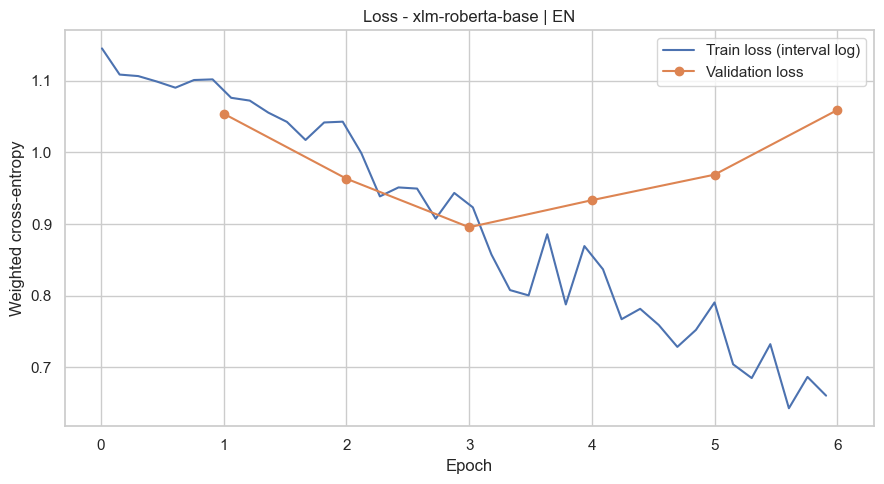

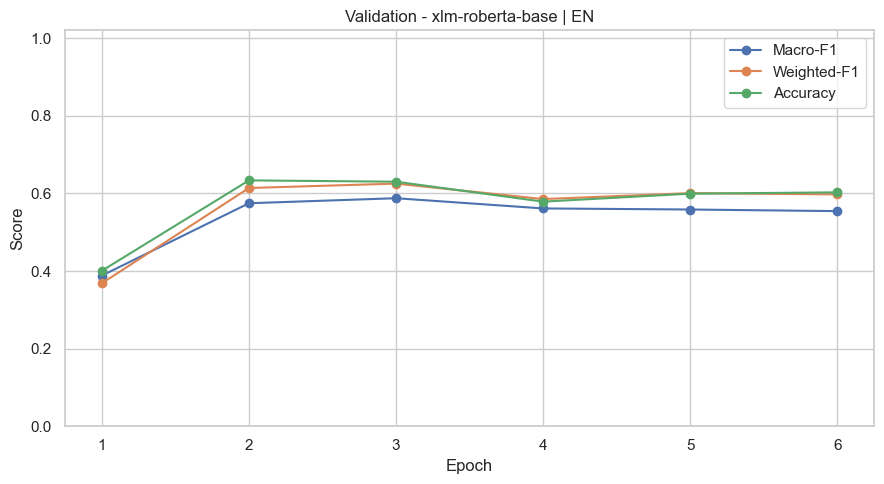

In [11]:
if 'en' in LANGUAGES:
    save_training_artifacts(en_experiment)


### 9.5 Evaluasi akhir validation dan test EN

Pakai checkpoint terbaik yang sudah dimuat. Simpan laporan tiap kelas,
confusion matrix, metrik agregat, dan prediksi validation/test.
Test diprediksi setelah pemilihan checkpoint selesai.


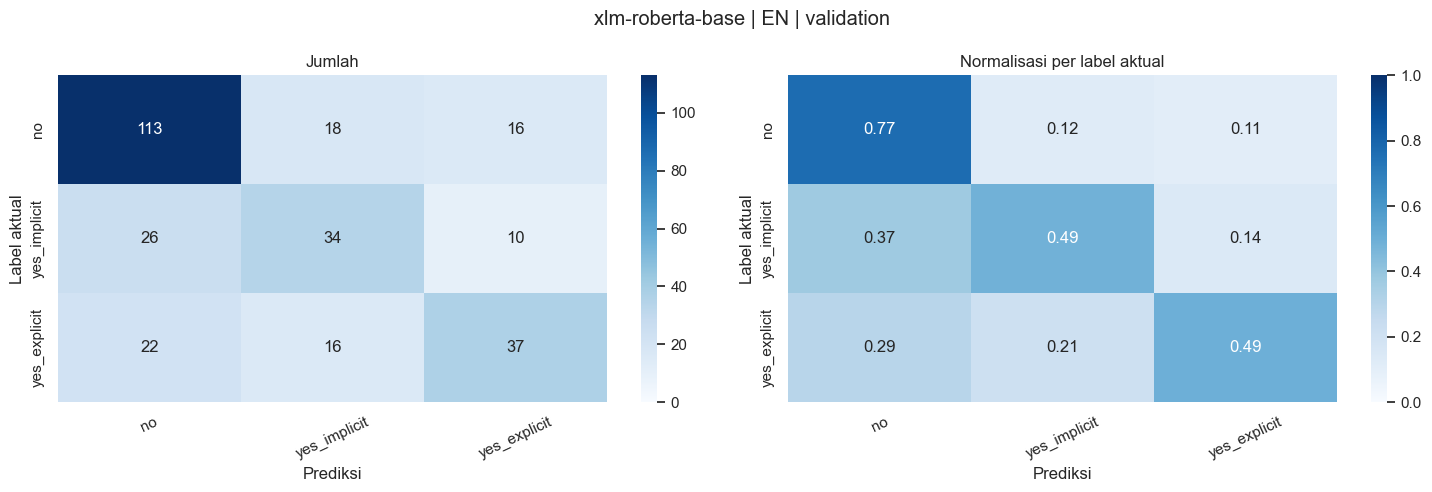

EN | validation


,accuracy,macro_f1,weighted_f1,loss
0,0.630137,0.587584,0.625253,0.895587


,precision,recall,f1-score,support
no,0.701863,0.768707,0.733766,147.000000
yes_implicit,0.500000,0.485714,0.492754,70.000000
yes_explicit,0.587302,0.493333,0.536232,75.000000
accuracy,0.630137,0.630137,0.630137,0.630137
macro avg,0.596388,0.582585,0.587584,292.000000
weighted avg,0.624046,0.630137,0.625253,292.000000


en - tokenisasi test akhir:   0%|          | 0/586 [00:00<?, ? examples/s]

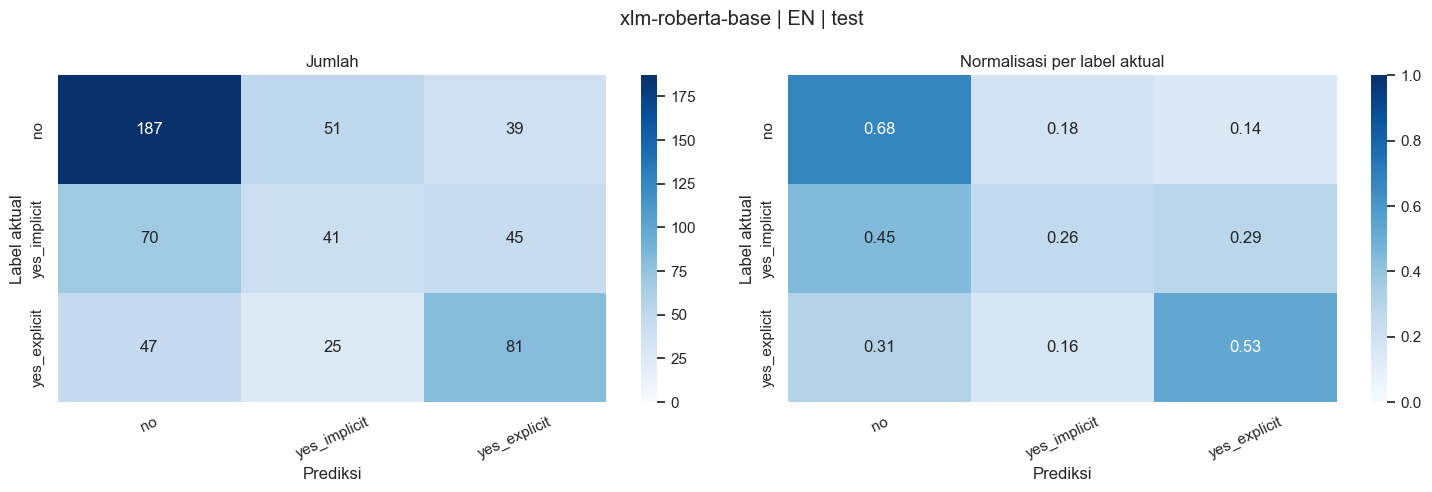

EN | test


,accuracy,macro_f1,weighted_f1,loss
0,0.527304,0.484506,0.517253,0.993271


,precision,recall,f1-score,support
no,0.615132,0.675090,0.643718,277.000000
yes_implicit,0.350427,0.262821,0.300366,156.000000
yes_explicit,0.490909,0.529412,0.509434,153.000000
accuracy,0.527304,0.527304,0.527304,0.527304
macro avg,0.485489,0.489108,0.484506,586.000000
weighted avg,0.512231,0.527304,0.517253,586.000000


In [12]:
if 'en' in LANGUAGES:
    evaluate_language(en_experiment)


### 9.6 Ekspor ZIP EN dan lepaskan RAM/GPU

Simpan manifest dan versi paket, buat ZIP, lalu lepaskan objek model dari memori.
Model tersimpan, hasil, dan checkpoint di disk tetap tersedia.
Download/salin ZIP dari cloud ke penyimpanan tim.


In [13]:
if 'en' in LANGUAGES:
    export_language(en_experiment)


Artefak: E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\en
ZIP: E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\xlm-roberta-base_en_20261020T105544Z_e1320f49.zip (756.1 MB)


E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\xlm-roberta-base_en_20261020T105544Z_e1320f49.zip

RAM/GPU sudah dilepas; bahasa berikutnya memulai model baru.


## 10. Eksperimen IT — Italian

Semua tahap berikut memakai **hanya split IT**.
Bagian dilewati jika `'it'` tidak ada dalam `LANGUAGES`.
Jalankan tahap 1–6 berurutan sampai ZIP tersimpan sebelum melanjutkan bahasa lain.


### 10.1 Baca split IT, audit, preprocessing, dan class weight

Muat `it-train.csv`, `it-val.csv`, dan `it-test.csv` dari
`it-splitting/`. Tampilkan ringkasan ukuran/label dan hitung class weight dari train saja.
Transformasi teks memakai aturan tetap dari konfigurasi.


In [14]:
if 'it' in LANGUAGES:
    it_experiment = prepare_language('it')
else:
    print('IT dilewati sesuai LANGUAGES.')


IT Italian | output: E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\it


,split,rows,no,yes_implicit,yes_explicit
0,train,1699,822,401,476
1,val,220,105,56,59
2,test,481,233,124,124


Class weights (hanya dari train): {'no': 0.6889699697494507, 'yes_implicit': 1.4123026132583618, 'yes_explicit': 1.1897759437561035}


### 10.2 Tokenisasi train dan validation IT

Dataset test menunggu tahap evaluasi akhir. Padding dilakukan dinamis saat batching.


In [15]:
if 'it' in LANGUAGES:
    tokenize_language(it_experiment)


it - tokenisasi train:   0%|          | 0/1699 [00:00<?, ? examples/s]

it - tokenisasi val:   0%|          | 0/220 [00:00<?, ? examples/s]

Train dan validation siap. Dynamic padding dilakukan oleh data collator.


### 10.3 Latih model IT dan pilih checkpoint dari validation

Sel ini menjalankan training saat nanti dieksekusi di cloud.
Early stopping memakai validation. Model terbaik disimpan untuk bahasa ini setelah training.


In [16]:
if 'it' in LANGUAGES:
    train_language(it_experiment)


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Melatih model baru: FacebookAI/xlm-roberta-base | bahasa: IT


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,1.096300,1.098277,0.477273,0.215385,0.308392
2,1.057600,1.058527,0.550000,0.432640,0.492488
3,0.942900,1.010964,0.577273,0.492690,0.540560
4,0.855500,1.049081,0.531818,0.458373,0.509814
5,0.834100,1.074245,0.563636,0.499048,0.544987
6,0.749900,1.117746,0.595455,0.543804,0.581875
7,0.654000,1.126387,0.563636,0.497289,0.542517
8,0.583600,1.234041,0.554545,0.476885,0.529167
9,0.589100,1.221058,0.572727,0.504371,0.552477


Checkpoint terpilih dari validation: E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\_checkpoints\it\checkpoint-642
Validation macro-F1 terbaik: 0.5438036083998817


### 10.4 Simpan dan tampilkan log serta grafik pelatihan IT

Simpan `training_history.csv/json`, `training_loss.png`, dan `validation_metrics.png`.
Model terbaik tetap tersedia untuk evaluasi akhir.


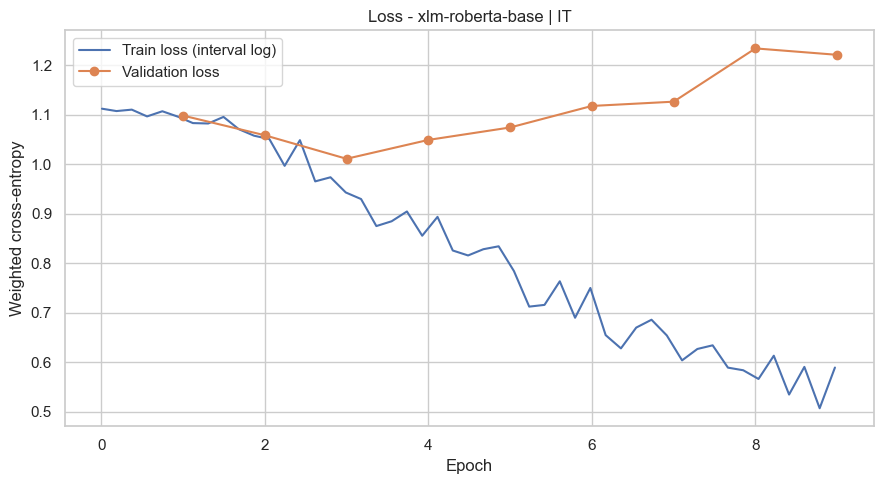

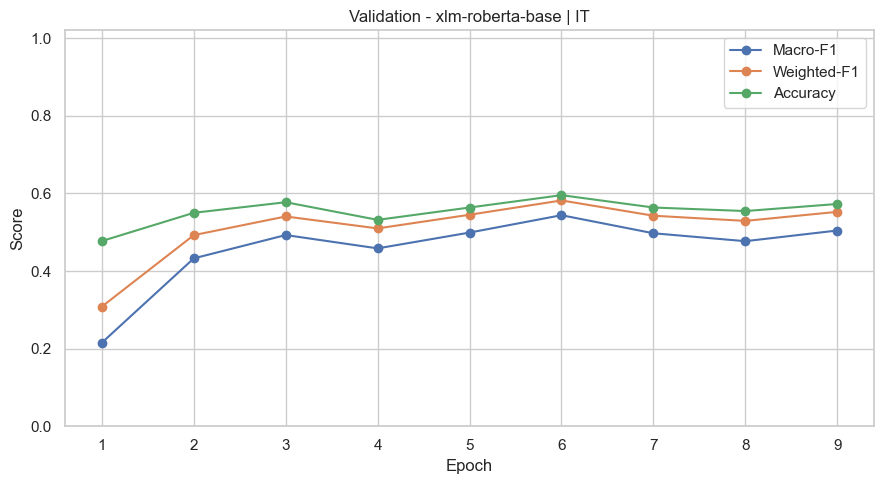

In [17]:
if 'it' in LANGUAGES:
    save_training_artifacts(it_experiment)


### 10.5 Evaluasi akhir validation dan test IT

Pakai checkpoint terbaik yang sudah dimuat. Simpan laporan tiap kelas,
confusion matrix, metrik agregat, dan prediksi validation/test.
Test diprediksi setelah pemilihan checkpoint selesai.


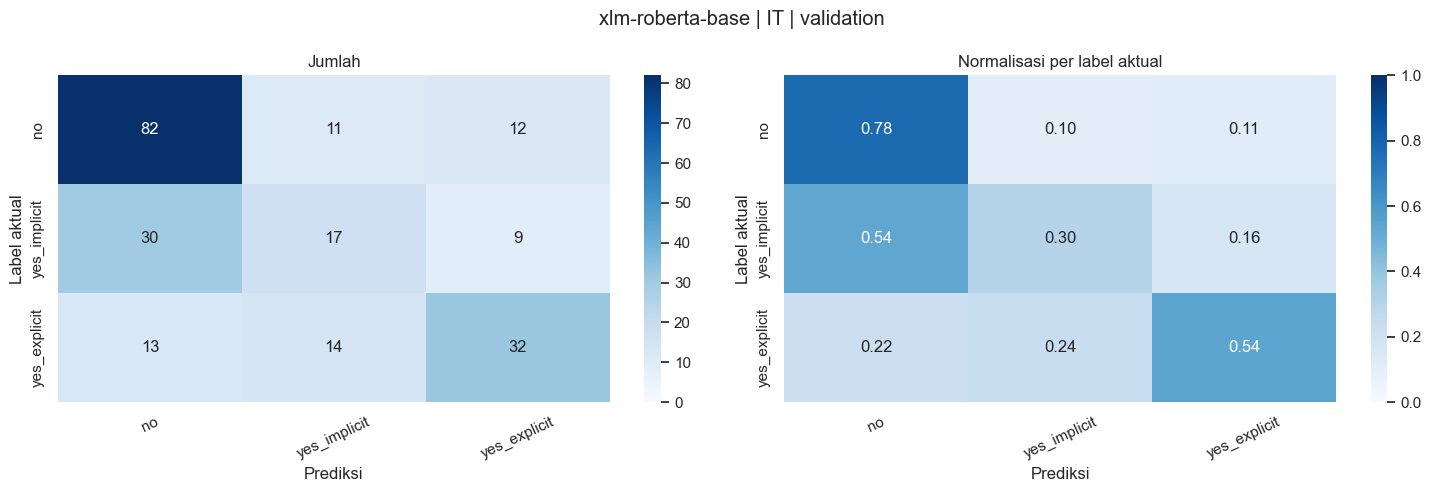

IT | validation


,accuracy,macro_f1,weighted_f1,loss
0,0.595455,0.543804,0.581875,1.117746


,precision,recall,f1-score,support
no,0.656000,0.780952,0.713043,105.000000
yes_implicit,0.404762,0.303571,0.346939,56.000000
yes_explicit,0.603774,0.542373,0.571429,59.000000
accuracy,0.595455,0.595455,0.595455,0.595455
macro avg,0.554845,0.542299,0.543804,220.000000
weighted avg,0.578042,0.595455,0.581875,220.000000


it - tokenisasi test akhir:   0%|          | 0/481 [00:00<?, ? examples/s]

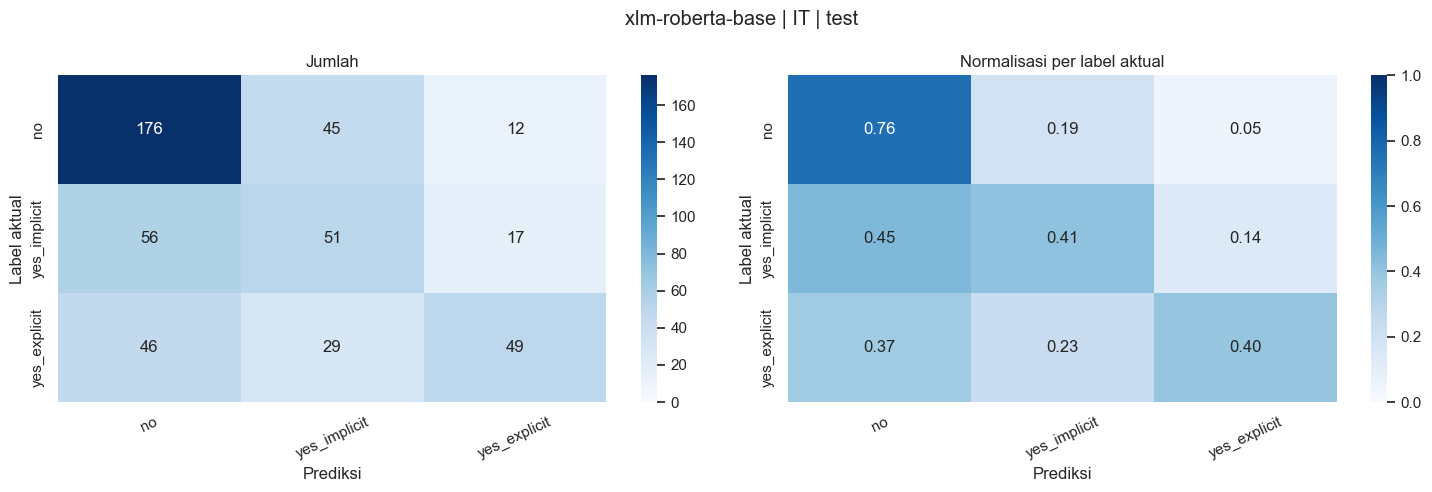

IT | test


,accuracy,macro_f1,weighted_f1,loss
0,0.573805,0.527877,0.564355,1.121397


,precision,recall,f1-score,support
no,0.633094,0.755365,0.688845,233.000000
yes_implicit,0.408000,0.411290,0.409639,124.000000
yes_explicit,0.628205,0.395161,0.485149,124.000000
accuracy,0.573805,0.573805,0.573805,0.573805
macro avg,0.556433,0.520605,0.527877,481.000000
weighted avg,0.573805,0.573805,0.564355,481.000000


In [18]:
if 'it' in LANGUAGES:
    evaluate_language(it_experiment)


### 10.6 Ekspor ZIP IT dan lepaskan RAM/GPU

Simpan manifest dan versi paket, buat ZIP, lalu lepaskan objek model dari memori.
Model tersimpan, hasil, dan checkpoint di disk tetap tersedia.
Download/salin ZIP dari cloud ke penyimpanan tim.


In [19]:
if 'it' in LANGUAGES:
    export_language(it_experiment)


Artefak: E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\it
ZIP: E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\xlm-roberta-base_it_20261020T105544Z_e1320f49.zip (752.8 MB)


E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\xlm-roberta-base_it_20261020T105544Z_e1320f49.zip

RAM/GPU sudah dilepas; bahasa berikutnya memulai model baru.


## 11. Eksperimen NL — Dutch

Semua tahap berikut memakai **hanya split NL**.
Bagian dilewati jika `'nl'` tidak ada dalam `LANGUAGES`.
Jalankan tahap 1–6 berurutan sampai ZIP tersimpan sebelum melanjutkan bahasa lain.


### 11.1 Baca split NL, audit, preprocessing, dan class weight

Muat `nl-train.csv`, `nl-val.csv`, dan `nl-test.csv` dari
`nl-splitting/`. Tampilkan ringkasan ukuran/label dan hitung class weight dari train saja.
Transformasi teks memakai aturan tetap dari konfigurasi.


In [20]:
if 'nl' in LANGUAGES:
    nl_experiment = prepare_language('nl')
else:
    print('NL dilewati sesuai LANGUAGES.')


NL Dutch | output: E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\nl


,split,rows,no,yes_implicit,yes_explicit
0,train,1556,784,335,437
1,val,226,109,55,62
2,test,456,234,97,125


Class weights (hanya dari train): {'no': 0.6615646481513977, 'yes_implicit': 1.548258662223816, 'yes_explicit': 1.1868802309036255}


### 11.2 Tokenisasi train dan validation NL

Dataset test menunggu tahap evaluasi akhir. Padding dilakukan dinamis saat batching.


In [21]:
if 'nl' in LANGUAGES:
    tokenize_language(nl_experiment)


nl - tokenisasi train:   0%|          | 0/1556 [00:00<?, ? examples/s]

nl - tokenisasi val:   0%|          | 0/226 [00:00<?, ? examples/s]

Train dan validation siap. Dynamic padding dilakukan oleh data collator.


### 11.3 Latih model NL dan pilih checkpoint dari validation

Sel ini menjalankan training saat nanti dieksekusi di cloud.
Early stopping memakai validation. Model terbaik disimpan untuk bahasa ini setelah training.


In [22]:
if 'nl' in LANGUAGES:
    train_language(nl_experiment)


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Melatih model baru: FacebookAI/xlm-roberta-base | bahasa: NL


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Weighted F1
1,1.102400,1.094900,0.500000,0.373283,0.436737
2,1.024200,1.056916,0.469027,0.454907,0.479209
3,0.939600,1.115936,0.535398,0.446256,0.498918
4,0.902100,1.084769,0.561947,0.517851,0.556026
5,0.831500,1.070786,0.530973,0.501401,0.536160
6,0.853000,1.132339,0.544248,0.499100,0.537971
7,0.803800,1.285485,0.539823,0.488486,0.532873


Checkpoint terpilih dari validation: E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\_checkpoints\nl\checkpoint-392
Validation macro-F1 terbaik: 0.5178508420208501


### 11.4 Simpan dan tampilkan log serta grafik pelatihan NL

Simpan `training_history.csv/json`, `training_loss.png`, dan `validation_metrics.png`.
Model terbaik tetap tersedia untuk evaluasi akhir.


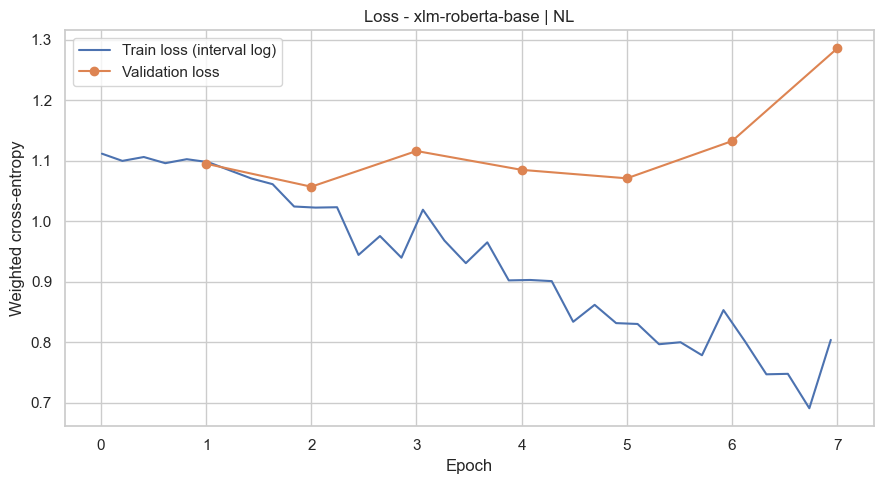

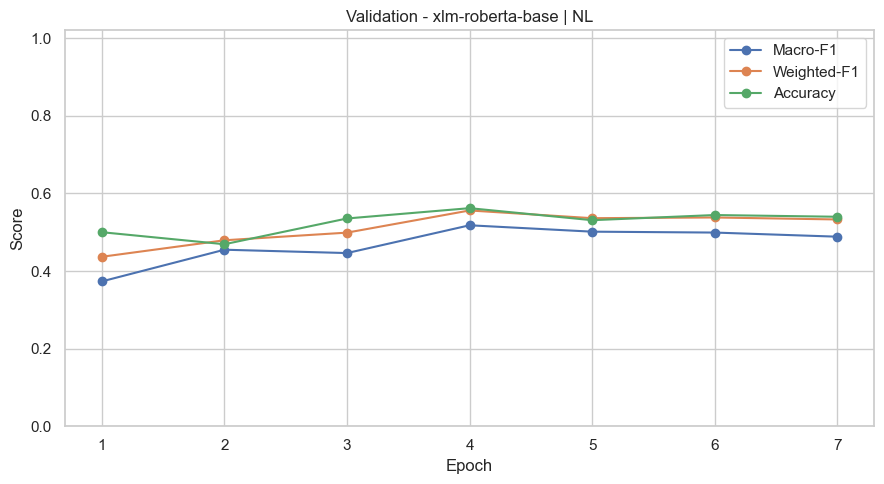

In [23]:
if 'nl' in LANGUAGES:
    save_training_artifacts(nl_experiment)


### 11.5 Evaluasi akhir validation dan test NL

Pakai checkpoint terbaik yang sudah dimuat. Simpan laporan tiap kelas,
confusion matrix, metrik agregat, dan prediksi validation/test.
Test diprediksi setelah pemilihan checkpoint selesai.


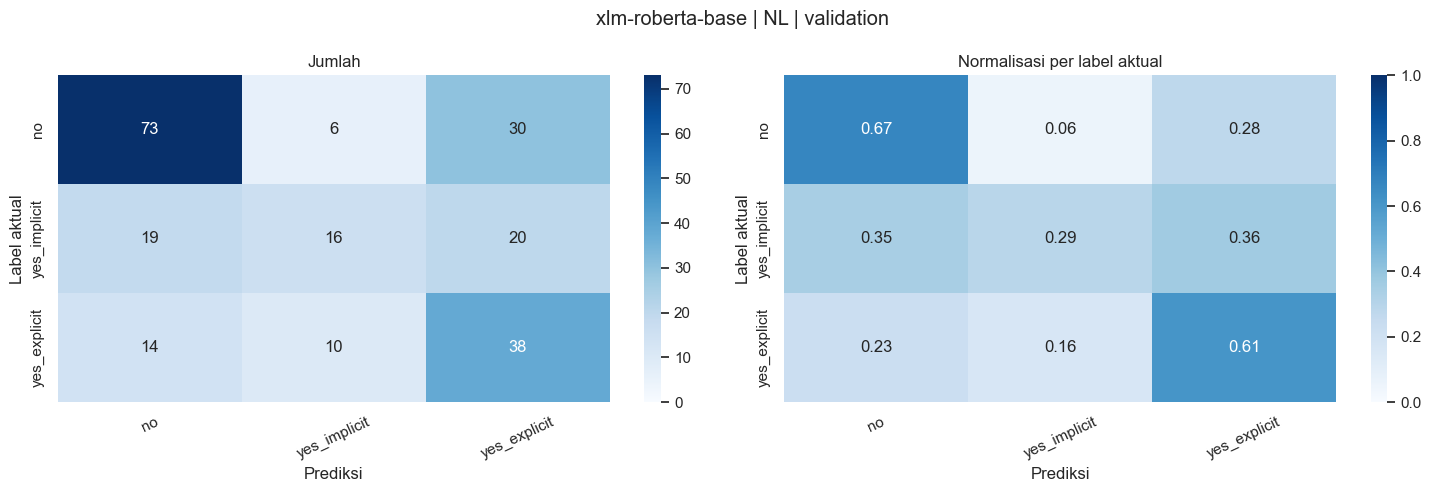

NL | validation


,accuracy,macro_f1,weighted_f1,loss
0,0.561947,0.517851,0.556026,1.084769


,precision,recall,f1-score,support
no,0.688679,0.669725,0.679070,109.000000
yes_implicit,0.500000,0.290909,0.367816,55.000000
yes_explicit,0.431818,0.612903,0.506667,62.000000
accuracy,0.561947,0.561947,0.561947,0.561947
macro avg,0.540166,0.524512,0.517851,226.000000
weighted avg,0.572295,0.561947,0.556026,226.000000


nl - tokenisasi test akhir:   0%|          | 0/456 [00:00<?, ? examples/s]

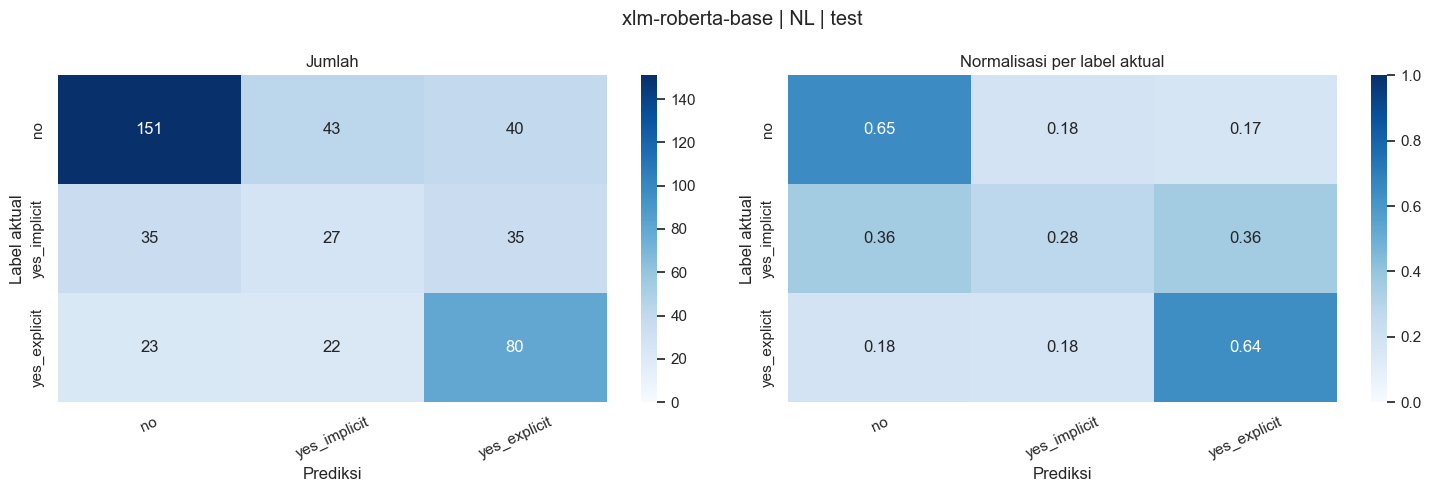

NL | test


,accuracy,macro_f1,weighted_f1,loss
0,0.565789,0.512953,0.567246,1.024296


,precision,recall,f1-score,support
no,0.722488,0.645299,0.681716,234.000000
yes_implicit,0.293478,0.278351,0.285714,97.000000
yes_explicit,0.516129,0.640000,0.571429,125.000000
accuracy,0.565789,0.565789,0.565789,0.565789
macro avg,0.510698,0.521217,0.512953,456.000000
weighted avg,0.574662,0.565789,0.567246,456.000000


In [24]:
if 'nl' in LANGUAGES:
    evaluate_language(nl_experiment)


### 11.6 Ekspor ZIP NL dan lepaskan RAM/GPU

Simpan manifest dan versi paket, buat ZIP, lalu lepaskan objek model dari memori.
Model tersimpan, hasil, dan checkpoint di disk tetap tersedia.
Download/salin ZIP dari cloud ke penyimpanan tim.


In [25]:
if 'nl' in LANGUAGES:
    export_language(nl_experiment)


Artefak: E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\nl
ZIP: E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\xlm-roberta-base_nl_20261020T105544Z_e1320f49.zip (751.5 MB)


E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\xlm-roberta-base_nl_20261020T105544Z_e1320f49.zip

RAM/GPU sudah dilepas; bahasa berikutnya memulai model baru.


## 12. Ringkasan hasil seluruh bahasa yang dipilih

Ringkasan untuk tiap bahasa dalam satu model. Validation dan test dilaporkan terpisah;
tidak dihitung rata-rata lintas bahasa secara otomatis.
Kolom test tidak dipakai untuk memilih hyperparameter atau checkpoint.
Gabungkan `experiment_comparison.csv` ketiga notebook nanti untuk analisis antarmodel.


In [26]:
incomplete = [lang for lang in LANGUAGES if not EXPERIMENTS.get(lang, {}).get('artifact_zip')]
if incomplete:
    raise RuntimeError(f'Selesaikan ekspor bahasa berikut terlebih dahulu: {incomplete}')
comparison_rows = []
for lang in LANGUAGES:
    state = EXPERIMENTS[lang]
    for split, values in state['metrics'].items():
        comparison_rows.append({
            'model': MODEL_NAME, 'language': lang, 'split': split, **values,
            'best_validation_macro_f1': state['best_validation_macro_f1'],
            'artifact_zip': state['artifact_zip'],
        })
comparison = pd.DataFrame(comparison_rows)
comparison_path = RUN_ROOT / 'experiment_comparison.csv'
comparison.to_csv(comparison_path, index=False)
display(comparison)
print('Ringkasan:', comparison_path)
display(FileLink(str(comparison_path)))


,model,language,split,accuracy,macro_f1,weighted_f1,loss,best_validation_macro_f1,artifact_zip
0,FacebookAI/xlm-roberta-base,en,validation,0.630137,0.587584,0.625253,0.895587,0.587584,E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\xlm-roberta-base_e...
1,FacebookAI/xlm-roberta-base,en,test,0.527304,0.484506,0.517253,0.993271,0.587584,E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\xlm-roberta-base_e...
2,FacebookAI/xlm-roberta-base,it,validation,0.595455,0.543804,0.581875,1.117746,0.543804,E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\xlm-roberta-base_i...
3,FacebookAI/xlm-roberta-base,it,test,0.573805,0.527877,0.564355,1.121397,0.543804,E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\xlm-roberta-base_i...
4,FacebookAI/xlm-roberta-base,nl,validation,0.561947,0.517851,0.556026,1.084769,0.517851,E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\xlm-roberta-base_n...
5,FacebookAI/xlm-roberta-base,nl,test,0.565789,0.512953,0.567246,1.024296,0.517851,E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\xlm-roberta-base_n...


Ringkasan: E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\experiment_comparison.csv


E:\Projek\PTM\TBP\Analisis\results\xlm-roberta-base\20261020T105544Z_e1320f49\experiment_comparison.csv

## 13. Unduh hasil di Colab (opsional)

Set `DOWNLOAD_ZIP=True` dan pilih satu bahasa untuk mengunduh ZIP-nya.
Ulangi pilihan untuk bahasa lain. Pada platform lain, salin ZIP dan ringkasan dari
`RUN_ROOT` melalui panel file/volume.
Jika bobot terlalu besar untuk download browser, arahkan output ke Drive atau volume persisten.


In [27]:
DOWNLOAD_ZIP = False
DOWNLOAD_LANGUAGE = 'en'
if DOWNLOAD_ZIP:
    if not IN_COLAB:
        raise RuntimeError('files.download khusus Colab. Gunakan panel file/volume platform ini.')
    if DOWNLOAD_LANGUAGE not in EXPERIMENTS or 'artifact_zip' not in EXPERIMENTS[DOWNLOAD_LANGUAGE]:
        raise ValueError('ZIP bahasa ini belum tersedia.')
    from google.colab import files
    files.download(EXPERIMENTS[DOWNLOAD_LANGUAGE]['artifact_zip'])


## 14. Membaca artefak dan memakai model kembali

```text
OUTPUT_ROOT/xlm-roberta-base/<run_id>/
├── en/                                  # Sama untuk it/ dan nl/
│   ├── best_model/                      # Bobot + config + tokenizer + preprocessing
│   ├── experiment_manifest.json
│   ├── preprocessing_config.json
│   ├── requirements_runtime.txt
│   ├── data_audit.json
│   ├── split_summary.csv
│   ├── class_weights.json
│   ├── training_metrics.json
│   ├── trainer_state.json
│   ├── training_history.csv / .json
│   ├── training_loss.png
│   ├── validation_metrics.png
│   ├── evaluation_results.json
│   ├── evaluation_summary.csv
│   ├── classification_report_validation.csv / .json
│   ├── classification_report_test.csv / .json
│   ├── confusion_matrix_validation.png / .csv
│   ├── confusion_matrix_validation_normalized.csv
│   ├── confusion_matrix_test.png / .csv
│   ├── confusion_matrix_test_normalized.csv
│   ├── validation_predictions.csv
│   ├── test_predictions.csv
│   └── README.txt
├── _checkpoints/<bahasa>/
├── <model>_<bahasa>_<run_id>.zip
└── experiment_comparison.csv
```

Untuk inferensi, muat `AutoTokenizer` dan `AutoModelForSequenceClassification` dari
`best_model/` bahasa yang sesuai. Terapkan aturan di `preprocessing_config.json`,
truncation dengan panjang sama, lalu `softmax` dan mapping label dari config model.
Preprocessing tidak otomatis dijalankan oleh tokenizer yang disimpan.
ZIP dan file prediksi memuat komentar asli untuk analisis kesalahan.

Referensi: [Trainer / TrainingArguments Transformers 4.57.1](https://huggingface.co/docs/transformers/v4.57.1/en/main_classes/trainer).
Checkpoint: [FacebookAI/xlm-roberta-base](https://huggingface.co/FacebookAI/xlm-roberta-base).
